# Sports Watch Classification
A compact adaptation of the semester project's Task 3: compare classifiers using the
three supplied, prepared CSV files. CRISP-DM structures the analysis; Gradio adds a local demo.

<a id="phase-1"></a>
## 1. Business Understanding
Predict `User of latest model`: **0 = older watch model, 1 = latest model**.
Compare baseline models, feature selection and limited tuning. Select by validation
**weighted F1**, then accuracy, retaining baseline candidates if tuning does not help.
Report the observed results without a target score. This classifies current usage, not future purchases.

In [1]:
from pathlib import Path
import hashlib
import platform
import warnings

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.ensemble import (
    BaggingClassifier, GradientBoostingClassifier, RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

get_ipython().run_line_magic("matplotlib", "inline")
ROOT = Path.cwd()
DATA = ROOT / "data"
TARGET = "User of latest model"
SEED = 42
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

<a id="phase-2"></a>
## 2. Data Understanding
Keep the supplied split: **585 training, 196 validation and 500 final-test rows**.
Each file contains 47 numeric features and the target. `num__` features are already
transformed; `cat__` features are one-hot encoded. Negative transformed values are valid.
Inspect training and validation here; reserve test outcomes for final evaluation.

,Rows,Columns
Training,585,48
Validation,196,48
Final test,500,48


,num__Age of customer,num__Swimming Hours per Week,num__Biking Hours per Week,num__Running Hours per Week,num__Total Training Hours per Week,num__VO2 Max,num__10k Running Time Prediction,num__Calories Burned per Week,num__Support Cases of Customer,num__Customer Years,...,cat__Preferred Training Daytime_Evening,cat__Preferred Training Daytime_Morning,cat__Subscription Type_Basic,cat__Subscription Type_Free,cat__Subscription Type_Premium,cat__Color of Watch_Black,cat__Color of Watch_White,cat__Synchronisation_No,cat__Synchronisation_Yes,User of latest model
0,0.044064,0.267697,-0.761761,-0.555236,-0.432693,0.042173,-0.095227,-0.671346,-1.371931,-0.574585,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0
1,0.974918,0.963983,0.713221,3.388496,1.120126,0.164716,-0.784299,2.308357,1.454053,0.102419,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1
2,-0.528769,-1.272759,-0.222770,0.285232,-0.307499,0.396187,-1.062064,-0.406344,0.747557,1.456426,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0


,count,mean,std,min,25%,50%,75%,max
num__Age of customer,585.0,-0.00,1.00,-2.96,-0.74,0.12,0.83,1.69
num__Swimming Hours per Week,585.0,-0.00,1.00,-1.37,-0.75,-0.18,0.58,3.90
num__Biking Hours per Week,585.0,0.00,1.00,-1.63,-0.78,-0.09,0.65,3.01
num__Running Hours per Week,585.0,-0.00,1.00,-1.50,-0.76,-0.16,0.64,3.98
num__Total Training Hours per Week,585.0,0.00,1.00,-1.19,-0.45,-0.15,0.26,9.28
num__VO2 Max,585.0,0.00,1.00,-2.29,-0.43,0.14,0.52,11.14
num__10k Running Time Prediction,585.0,0.00,1.00,-2.20,-0.71,-0.21,0.61,2.87
num__Calories Burned per Week,585.0,-0.00,1.00,-2.24,-0.71,-0.12,0.64,3.07
num__Support Cases of Customer,585.0,-0.00,1.00,-1.37,-0.67,0.04,0.75,1.45
num__Customer Years,585.0,-0.00,1.00,-1.25,-0.91,-0.24,0.78,2.47


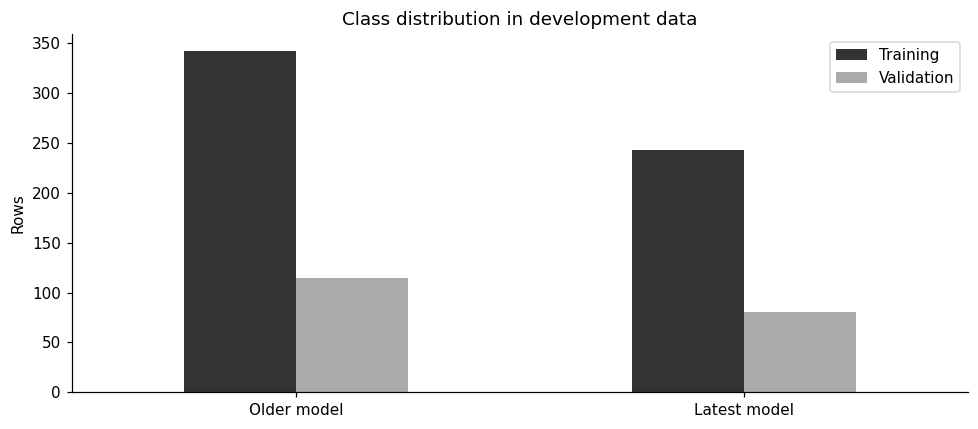

In [2]:
files = {"Training": "train_task3.csv", "Validation": "validation_task3.csv",
         "Final test": "final_test_task3.csv"}
frames = {name: pd.read_csv(DATA / filename) for name, filename in files.items()}
input_hashes = {filename: hashlib.sha256((DATA / filename).read_bytes()).hexdigest()
                for filename in files.values()}
train, validation, test = (frames[name] for name in files)
display(pd.DataFrame({name: {"Rows": len(frame), "Columns": len(frame.columns)}
                      for name, frame in frames.items()}).T)
display(train.head(3))
display(train.describe().T.round(2))
class_counts = pd.DataFrame({"Training": train[TARGET].value_counts(),
                             "Validation": validation[TARGET].value_counts()}).sort_index()
class_counts.index = ["Older model", "Latest model"]
class_counts.plot.bar(rot=0, color=["#333333", "#aaaaaa"], ylabel="Rows",
                      title="Class distribution in development data")
plt.tight_layout()
plt.show()

<a id="phase-3"></a>
## 3. Data Preparation
Use the files as supplied: separate features and target without a new split, imputation
or scaling. Check schema, finite values, labels and duplicate feature rows. Retain duplicates
to preserve the original data basis; group identical training features for internal CV.
Earlier Task-2 preparation includes steps learned before splitting; its effects remain
in these exports. See the [process overview](CRISP-DM-Process-Overview.md#3-data-preparation).
Row checks cannot establish independence between people.

In [3]:
columns = train.columns.drop(TARGET).tolist()
assert len(columns) == 47
for name, frame in frames.items():
    assert frame.columns.tolist() == train.columns.tolist(), f"Different schema: {name}"
    assert np.isfinite(frame.to_numpy(dtype=float)).all(), f"Invalid values: {name}"
    assert frame[TARGET].isin([0, 1]).all(), f"Invalid target: {name}"

X_train, y_train = train[columns], train[TARGET].astype(int)
X_val, y_val = validation[columns], validation[TARGET].astype(int)
X_test, y_test = test[columns], test[TARGET].astype(int)
# Identical feature rows share a group, without changing the supplied CSV files.
train_groups = pd.util.hash_pandas_object(X_train, index=False)
row_hashes = {name: set(pd.util.hash_pandas_object(frame[columns], index=False))
              for name, frame in frames.items()}
duplicate_check = pd.DataFrame({
    name: {"Duplicate feature rows": int(frame[columns].duplicated().sum())}
    for name, frame in frames.items()
}).T
display(duplicate_check)
for left, right in [("Training", "Validation"), ("Training", "Final test"),
                    ("Validation", "Final test")]:
    print(f"Identical feature rows — {left} / {right}: "
          f"{len(row_hashes[left] & row_hashes[right])}")

,Duplicate feature rows
Training,1
Validation,0
Final test,1


Identical feature rows — Training / Validation: 0
Identical feature rows — Training / Final test: 0
Identical feature rows — Validation / Final test: 0


<a id="phase-4"></a>
## 4. Modeling
Keep the semester project's eight model families and three stages: baseline, feature
selection and tuning. A random forest ranks features; retain enough to reach 80% of
cumulative importance. Fit selection inside each CV fold. Use small parameter grids and
five stratified group folds within training, keeping identical observations together.
The supplied validation file ranks all candidates; the final test follows selection.
A majority classifier adds context.

In [4]:
class ImportanceSelector(TransformerMixin, BaseEstimator):
    """Keep the training-based random-forest ranking up to 80% importance."""
    def __init__(self, coverage=0.80, random_state=SEED):
        self.coverage = coverage
        self.random_state = random_state

    def fit(self, X, y):
        forest = RandomForestClassifier(n_estimators=100, random_state=self.random_state)
        forest.fit(X, y)
        self.importances_ = pd.Series(forest.feature_importances_, index=X.columns)
        ranked = self.importances_.sort_values(ascending=False)
        count = np.searchsorted(ranked.cumsum().to_numpy(), self.coverage) + 1
        self.columns_ = ranked.head(int(count)).index.tolist()
        return self

    def transform(self, X):
        return X[self.columns_]


models = {
    "Decision tree": DecisionTreeClassifier(random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=100, random_state=SEED),
    "Gradient boosting": GradientBoostingClassifier(random_state=SEED),
    "Bagging": BaggingClassifier(n_estimators=50, random_state=SEED),
    "Logistic regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Naive Bayes": GaussianNB(),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "MLP": MLPClassifier(hidden_layer_sizes=(100,), max_iter=2000, random_state=SEED),
}
results, candidates = [], {}


def fit_checked(estimator, X, y):
    """Keep convergence diagnostics visible without repeated warning tracebacks."""
    with warnings.catch_warnings(record=True) as messages:
        warnings.simplefilter("always", ConvergenceWarning)
        estimator.fit(X, y)
    convergence_count = 0
    for message in messages:
        if issubclass(message.category, ConvergenceWarning):
            convergence_count += 1
        else:
            warnings.warn(message.message, message.category, stacklevel=2)
    return estimator, convergence_count


def evaluate(name, stage, estimator):
    fitted, convergence_count = fit_checked(clone(estimator), X_train, y_train)
    training, prediction = fitted.predict(X_train), fitted.predict(X_val)
    train_f1 = f1_score(y_train, training, average="weighted")
    val_f1 = f1_score(y_val, prediction, average="weighted")
    results.append({"Model": name, "Stage": stage,
                    "Train accuracy": accuracy_score(y_train, training),
                    "Validation accuracy": accuracy_score(y_val, prediction),
                    "Train F1": train_f1, "Validation F1": val_f1,
                    "F1 gap": train_f1 - val_f1,
                    "Convergence warnings": convergence_count})
    candidates[(name, stage)] = fitted


dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_prediction = dummy.predict(X_val)
print(f"Majority baseline — validation accuracy: {accuracy_score(y_val, dummy_prediction):.3f}; "
      f"weighted F1: {f1_score(y_val, dummy_prediction, average='weighted'):.3f}")

Majority baseline — validation accuracy: 0.587; weighted F1: 0.434


,Model,Stage,Train accuracy,Validation accuracy,Train F1,Validation F1,F1 gap,Convergence warnings
0,Decision tree,Baseline,1.000,0.679,1.000,0.681,0.319,0
1,Decision tree,Feature selection,1.000,0.648,1.000,0.650,0.350,0
2,Random forest,Baseline,1.000,0.770,1.000,0.769,0.231,0
3,Random forest,Feature selection,1.000,0.765,1.000,0.765,0.235,0
4,Gradient boosting,Baseline,0.949,0.781,0.948,0.781,0.167,0
5,Gradient boosting,Feature selection,0.932,0.781,0.931,0.781,0.150,0
6,Bagging,Baseline,1.000,0.776,1.000,0.776,0.224,0
7,Bagging,Feature selection,0.998,0.791,0.998,0.792,0.207,0
8,Logistic regression,Baseline,0.781,0.791,0.779,0.790,-0.011,0
9,Logistic regression,Feature selection,0.778,0.770,0.774,0.769,0.006,0


Selected 16 of 47 features on training data.


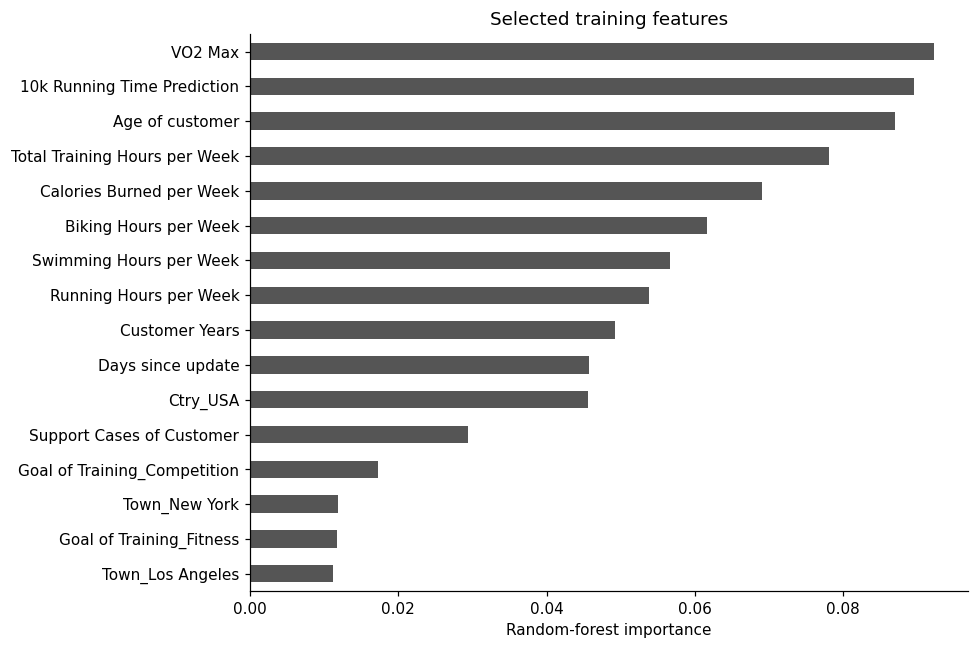

In [5]:
for name, model in models.items():
    evaluate(name, "Baseline", Pipeline([("model", model)]))
    evaluate(name, "Feature selection", Pipeline([
        ("selection", ImportanceSelector()), ("model", model),
    ]))
comparison = pd.DataFrame(results)
display(comparison.round(3))

selector = candidates[("Random forest", "Feature selection")].named_steps["selection"]
print(f"Selected {len(selector.columns_)} of {len(columns)} features on training data.")
importance = selector.importances_.loc[selector.columns_].sort_values()
importance.index = importance.index.str.replace(r"^(num|cat)__", "", regex=True)
importance.plot.barh(figsize=(9, 6), color="#555555", xlabel="Random-forest importance",
                     title="Selected training features")
plt.tight_layout()
plt.show()

In [6]:
# Compact grids keep the original tuning stage practical to reproduce.
grids = {
    "Decision tree": {"max_depth": [3, 5, None], "min_samples_leaf": [1, 5]},
    "Random forest": {"max_depth": [5, None], "min_samples_leaf": [1, 5]},
    "Gradient boosting": {"learning_rate": [0.03, 0.1], "max_depth": [2, 3]},
    "Bagging": {"n_estimators": [50, 100], "max_samples": [0.7, 1.0]},
    "Logistic regression": {"C": [0.01, 0.1, 1.0, 10.0]},
    "Naive Bayes": {"var_smoothing": [1e-12, 1e-9, 1e-7]},
    "kNN": {"n_neighbors": [3, 5, 11], "weights": ["uniform", "distance"]},
    "MLP": {"hidden_layer_sizes": [(50,), (100,)], "alpha": [0.0001, 0.001]},
}
# These inner folds use only the supplied training file.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train, train_groups))
assert all(set(train_groups.iloc[a]).isdisjoint(train_groups.iloc[b]) for a, b in cv_splits)
display(pd.DataFrame([{"CV fold": i, "Fit rows": len(a), "Held-out rows": len(b),
                       "Shared feature groups": len(set(train_groups.iloc[a]) & set(train_groups.iloc[b]))}
                      for i, (a, b) in enumerate(cv_splits, start=1)]))
tuning = []
for name, model in models.items():
    pipeline = Pipeline([("selection", ImportanceSelector()), ("model", model)])
    grid = GridSearchCV(pipeline, {f"model__{key}": values for key, values in grids[name].items()},
                        scoring="f1_weighted", cv=cv_splits, n_jobs=1, error_score="raise")
    grid, convergence_count = fit_checked(grid, X_train, y_train)
    evaluate(name, "Tuned", grid.best_estimator_)
    tuning.append({"Model": name, "CV weighted F1": grid.best_score_,
                   "Search convergence warnings": convergence_count,
                   "Parameters": grid.best_params_})
    print(f"Finished tuning: {name}")
display(pd.DataFrame(tuning).round(3))

,CV fold,Fit rows,Held-out rows,Shared feature groups
0,1,468,117,0
1,2,468,117,0
2,3,468,117,0
3,4,468,117,0
4,5,468,117,0


Finished tuning: Decision tree


Finished tuning: Random forest


Finished tuning: Gradient boosting


Finished tuning: Bagging


Finished tuning: Logistic regression


Finished tuning: Naive Bayes


Finished tuning: kNN


Finished tuning: MLP


,Model,CV weighted F1,Search convergence warnings,Parameters
0,Decision tree,0.706,0,"{'model__max_depth': 5, 'model__min_samples_le..."
1,Random forest,0.755,0,"{'model__max_depth': None, 'model__min_samples..."
2,Gradient boosting,0.762,0,"{'model__learning_rate': 0.1, 'model__max_dept..."
3,Bagging,0.758,0,"{'model__max_samples': 1.0, 'model__n_estimato..."
4,Logistic regression,0.762,0,{'model__C': 0.1}
5,Naive Bayes,0.724,0,{'model__var_smoothing': 1e-12}
6,kNN,0.728,0,"{'model__n_neighbors': 11, 'model__weights': '..."
7,MLP,0.708,2,"{'model__alpha': 0.001, 'model__hidden_layer_s..."


Convergence warnings count optimizer iteration-limit warnings for each fit; the tuning table counts them across the search. MLP results may reflect this limit.


,Model,Stage,Train accuracy,Validation accuracy,Train F1,Validation F1,F1 gap,Convergence warnings,Absolute F1 gap
0,kNN,Tuned,0.776,0.806,0.767,0.802,-0.034,0,0.034
1,MLP,Baseline,1.000,0.801,1.000,0.801,0.199,0,0.199
2,Gradient boosting,Tuned,0.868,0.796,0.868,0.796,0.072,0,0.072
3,Bagging,Feature selection,0.998,0.791,0.998,0.792,0.207,0,0.207
4,Bagging,Tuned,1.000,0.791,1.000,0.791,0.209,0,0.209
5,Logistic regression,Baseline,0.781,0.791,0.779,0.790,-0.011,0,0.011
6,Logistic regression,Tuned,0.786,0.791,0.783,0.789,-0.006,0,0.006
7,Gradient boosting,Feature selection,0.932,0.781,0.931,0.781,0.150,0,0.150
8,Gradient boosting,Baseline,0.949,0.781,0.948,0.781,0.167,0,0.167
9,Bagging,Baseline,1.000,0.776,1.000,0.776,0.224,0,0.224


Selected: kNN / Tuned


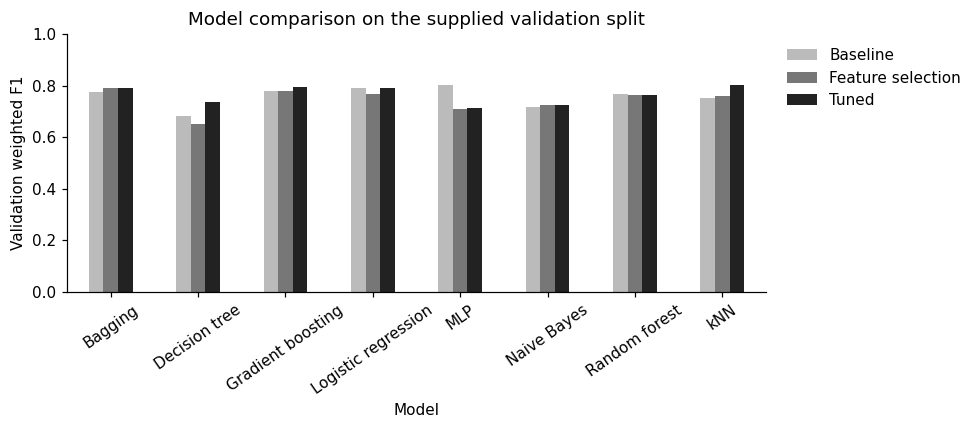

In [7]:
comparison = pd.DataFrame(results)
print("Convergence warnings count optimizer iteration-limit warnings for each fit; "
      "the tuning table counts them across the search. MLP results may reflect this limit.")
comparison["Absolute F1 gap"] = comparison["F1 gap"].abs()
comparison = comparison.sort_values(
    ["Validation F1", "Validation accuracy", "Absolute F1 gap"],
    ascending=[False, False, True], kind="stable",
).reset_index(drop=True)
best = comparison.iloc[0]
selected_model = candidates[(best["Model"], best["Stage"])]
display(comparison.round(3))
print(f"Selected: {best['Model']} / {best['Stage']}")
scores_by_stage = comparison.pivot(index="Model", columns="Stage", values="Validation F1")
scores_by_stage[["Baseline", "Feature selection", "Tuned"]].plot.bar(
    rot=35, color=["#bbbbbb", "#777777", "#222222"],
    ylabel="Validation weighted F1", title="Model comparison on the supplied validation split",
)
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

<a id="phase-5"></a>
## 5. Evaluation
Refit the selected configuration, including feature selection if present, on training plus
validation. Evaluate that fixed model on all 500 test rows. Inspect accuracy, weighted F1
and class-specific errors. The test file was used in earlier project versions; this is a
reproducible course evaluation, not a new untouched benchmark. Inherited preprocessing
limitations and missing person identifiers limit conclusions about independent performance.

Final-fit convergence warnings: 0


,Accuracy,Weighted F1
Validation (selection),0.806,0.802
Final test (after refit),0.738,0.731


Features after refitting selection: 15
              precision    recall  f1-score   support

 Older model      0.749     0.850     0.796       301
Latest model      0.715     0.568     0.633       199

    accuracy                          0.738       500
   macro avg      0.732     0.709     0.715       500
weighted avg      0.735     0.738     0.731       500



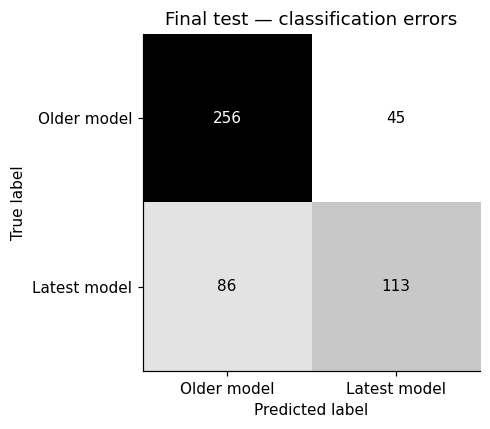

In [8]:
X_development = pd.concat([X_train, X_val], ignore_index=True)
y_development = pd.concat([y_train, y_val], ignore_index=True)
final_model, final_warnings = fit_checked(clone(selected_model), X_development, y_development)
print(f"Final-fit convergence warnings: {final_warnings}")
final_prediction = final_model.predict(X_test)
test_accuracy = accuracy_score(y_test, final_prediction)
test_f1 = f1_score(y_test, final_prediction, average="weighted")
display(pd.DataFrame({"Accuracy": [best["Validation accuracy"], test_accuracy],
                      "Weighted F1": [best["Validation F1"], test_f1]},
                     index=["Validation (selection)", "Final test (after refit)"]).round(3))
if "selection" in final_model.named_steps:
    print(f"Features after refitting selection: {len(final_model.named_steps['selection'].columns_)}")
print(classification_report(y_test, final_prediction, labels=[0, 1],
                            target_names=["Older model", "Latest model"], digits=3))
ConfusionMatrixDisplay.from_predictions(
    y_test, final_prediction, labels=[0, 1], display_labels=["Older model", "Latest model"],
    cmap="Greys", colorbar=False,
)
plt.title("Final test — classification errors")
plt.tight_layout()
plt.show()

In [9]:
baseline_best = comparison.loc[comparison["Stage"] == "Baseline"].iloc[0]
print(f"Strongest baseline: {baseline_best['Model']} "
      f"(validation weighted F1 {baseline_best['Validation F1']:.3f}).")
print(f"Selected configuration: {best['Model']} / {best['Stage']} "
      f"(validation weighted F1 {best['Validation F1']:.3f}).")
print(f"Final test: accuracy {test_accuracy:.3f}, weighted F1 {test_f1:.3f}.")
missed_latest = int(((y_test == 1) & (final_prediction == 0)).sum())
actual_latest = int((y_test == 1).sum())
print(f"Missed latest-model users: {missed_latest} of {actual_latest}.")
print("Feature selection and tuning do not automatically improve validation results.")
print("Small score differences on one repeatedly used validation split are not proof of superiority.")

Strongest baseline: MLP (validation weighted F1 0.801).
Selected configuration: kNN / Tuned (validation weighted F1 0.802).
Final test: accuracy 0.738, weighted F1 0.731.
Missed latest-model users: 86 of 199.
Feature selection and tuning do not automatically improve validation results.
Small score differences on one repeatedly used validation split are not proof of superiority.


<a id="phase-6"></a>
## 6. Deployment
Export the experiment results to `results.json` for a small Gradio model-comparison explorer.
It shows training and validation scores across baseline, feature selection and tuning;
all fitting and evaluation remain in this notebook. The app reads the exported results.
Recreate them by running this notebook in the locked uv environment.

In [10]:
report = {
    "metric": "Weighted F1",
    "models": list(models),
    "stages": ["Baseline", "Feature selection", "Tuned"],
    "comparison": comparison.to_dict(orient="records"),
    "search_warnings": {row["Model"]: row["Search convergence warnings"] for row in tuning},
    "selected": {"model": str(best["Model"]), "stage": str(best["Stage"]),
                 "test_accuracy": test_accuracy, "test_f1_weighted": test_f1},
    "rows": {name: len(frame) for name, frame in frames.items()},
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit-learn": sklearn.__version__},
    "input_hashes": input_hashes,
}
(ROOT / "results.json").write_text(json.dumps(report, indent=2, allow_nan=False) + "\n")
restored = json.loads((ROOT / "results.json").read_text())
assert restored["comparison"] == comparison.to_dict(orient="records")
assert restored["selected"]["test_accuracy"] == test_accuracy
assert restored["selected"]["test_f1_weighted"] == test_f1
assert all(hashlib.sha256((DATA / name).read_bytes()).hexdigest() == checksum
           for name, checksum in input_hashes.items())
print("Saved results.json; all 24 comparison records match and the three CSV files are unchanged.")

Saved results.json; all 24 comparison records match and the three CSV files are unchanged.
